# DSPy Dual-Model Optimization: Qwen 3.5 (2B) Proposer + Nimble (9B) Decision Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dustinober1/Arg_Me/blob/main/notebooks/08_dspy_mipro_copro_optimization.ipynb)

### Executive Summary & Problem Formulation
In competitive debate stance detection on `webis/args_me`, debaters frequently employ **adversarial quotations** (e.g., quoting "Pro argues..." only to debunk it) and **procedural chatter** (turn negotiations, forfeits). Hand-crafted prompts struggle to balance these linguistic nuances.

In this notebook, we implement an **Asymmetric Dual-Model DSPy Architecture**:
1. **Prompt Proposal Model (`prompt_model`)**: **`qwen3.5:2b`** (Ollama) serves as the meta-optimizer and prompt engineer. It generates candidate dialectic instructions, criteria variations, and analyzes edge cases.
2. **Task Evaluation Model (`task_model`)**: **`nimble:latest`** (Bespoke Labs 9B) serves as the high-throughput decision worker via `/v1/systemone`, scoring discrete stance choices in zero generation tokens.

### Optimization Strategies Explored:
- **COPRO (Coordinate Prompt Optimization)**: Qwen 3.5 proposes $B$ coordinate instruction variations, Nimble evaluates them on validation arguments, and the highest-accuracy instruction is selected.
- **MIPROv2 (Multi-prompt Instruction Proposal & Optimization)**: Jointly optimizes prompt criteria and bootstrapped debate exemplars.
- **Baseline Comparison**: Zero-shot unoptimized prompt on Nimble 9B.

In [7]:
# 1. Environment Detection, Auto-Cloning & Dependencies
import sys
import os
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if IN_COLAB:
    print("Provisioning dependencies inside Google Colab runtime...")
    !pip install -q datasets huggingface_hub pandas pyarrow scikit-learn requests matplotlib seaborn tqdm dspy optuna
    if not os.path.exists("Arg_Me") and not os.path.exists("src"):
        print("Cloning Arg_Me repository into Colab...")
        !git clone https://github.com/dustinober1/Arg_Me.git
        %cd Arg_Me
    elif os.path.exists("Arg_Me") and not os.path.exists("src"):
        %cd Arg_Me
    if "/content/Arg_Me" not in sys.path:
        sys.path.insert(0, "/content/Arg_Me")
    print("Colab environment configured! Current working directory:", os.getcwd())
else:
    print("Running in local environment.")

Running in local environment.


In [8]:
# 2. Imports and Ollama Dual-Model Verification
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Ensure project root in sys.path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import dspy
from src.dataset_loader import load_sample_df
from src.dspy_mipro_copro import (
    ArgumentStanceSignature,
    NimbleStancePredictor,
    NimbleDecisionLM,
    QwenProposerLM,
    stance_accuracy_metric,
    stance_dialectic_metric,
    df_to_dspy_dataset,
)

OLLAMA_URL = os.environ.get("OLLAMA_BASE_URL", "http://localhost:11434").rstrip("/")
try:
    res = requests.get(f"{OLLAMA_URL}/api/tags", timeout=3.0)
    models = [m["name"] for m in res.json().get("models", [])]
    print("Connected to Ollama! Available models:", models)
    has_qwen = any("qwen3.5:2b" in m for m in models)
    has_nimble = any("nimble" in m for m in models)
    print(f"Prompt Proposer Model (qwen3.5:2b) ready: {has_qwen}")
    print(f"Decision Task Model (nimble:latest) ready: {has_nimble}")
except Exception as e:
    print(f"Ollama status notice: {e}")

Connected to Ollama! Available models: ['qwen3.5:2b', 'nimble:latest', 'tev1:4b', 'gemma4:26b-a4b-it-qat']
Prompt Proposer Model (qwen3.5:2b) ready: True
Decision Task Model (nimble:latest) ready: True


In [9]:
# 3. Load Debate Arguments & Prepare Train / Val / Test Splits
df_raw = load_sample_df()
print(f"Loaded {len(df_raw)} arguments from args.me corpus")
print("Class balance:", df_raw["stance"].value_counts().to_dict())

# Train (candidates for proposals/few-shots), Val (for scoring prompt candidates), Test (unseen holdout)
train_df, temp_df = train_test_split(df_raw, test_size=0.5, random_state=42, stratify=df_raw["stance"])
val_df, test_df = train_test_split(temp_df, test_size=0.6, random_state=42, stratify=temp_df["stance"])

trainset = df_to_dspy_dataset(train_df)
valset = df_to_dspy_dataset(val_df)
testset = df_to_dspy_dataset(test_df)

print(f"DSPy Splits -> Train: {len(trainset)}, Val: {len(valset)}, Test: {len(testset)}")

Streaming 500 records from webis/args_me...
Collected 500 premise rows across 500 argument records.
Loaded 500 arguments from args.me corpus
Class balance: {'CON': 254, 'PRO': 246}
DSPy Splits -> Train: 250, Val: 100, Test: 150


## 1. Baseline Zero-Shot Nimble 9B
We establish our control baseline using generic, unoptimized stance instructions.

In [10]:
# 4. Baseline Evaluation
baseline_pipeline = NimbleStancePredictor(
    model_name="nimble",
    custom_instruction="Classify the premise as PRO (affirms resolution) or CON (opposes resolution).",
)

EVAL_SAMPLE_SIZE = 50  # Set to 50, 100, or full len(test_df) as desired
baseline_metrics, _ = baseline_pipeline.evaluate_df(
    test_df,
    sample_size=EVAL_SAMPLE_SIZE,
    pipeline_title="Baseline Nimble 9B (Zero-Shot)",
)
print(baseline_metrics)

Evaluating Baseline Nimble 9B (Zero-Shot):   0%|          | 0/50 [00:00<?, ?it/s]2026/10/12 20:35:07 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
2026/10/12 20:35:07 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
2026/10/12 20:35:07 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
Evaluating Baseline Nimble 9B (Zero-Shot):   6%|▌         | 3/50 [00:00<00:01, 27.26it/s]2026/10/12 20:35:07 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
2026/10/12 20:35:07 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
2026/10/12 20:35:07 

EvaluationMetrics(model_name='Baseline Nimble 9B (Zero-Shot)', accuracy=0.84, macro_f1=0.8397, macro_precision=0.84, macro_recall=0.8422, pro_f1=np.float64(0.8462), con_f1=np.float64(0.8333), roc_auc=0.8615, confusion_mat=[[20, 3], [5, 22]])


## 2. COPRO (Coordinate Prompt Optimization) via Qwen 3.5 (2B)

In COPRO:
1. **`qwen3.5:2b`** actively generates candidate dialectic prompt instructions focusing on adversarial refutation.
2. **`nimble:latest`** scores each candidate on the validation set.
3. The candidate instruction achieving the highest validation accuracy is crowned as the optimized instruction.

In [11]:
# 5. Qwen 3.5 (2B) Coordinate Prompt Proposal & Validation Search
proposer = QwenProposerLM(model="qwen3.5:2b")

print("Generating coordinate prompt proposals using Qwen 3.5 (2B)...")
base_inst = "Classify the premise as PRO or CON relative to the motion."
candidate_instructions = proposer.propose_candidate_instructions(
    current_instruction=base_inst,
    n_candidates=4,
)

print("\n--- PROPOSED CANDIDATES BY QWEN 3.5 (2B) ---")
for i, cand in enumerate(candidate_instructions, 1):
    print(f"[{i}] {cand}")

print("\nEvaluating Candidate Instructions against validation set using Nimble 9B...")
copro_results = []
for i, cand in enumerate(candidate_instructions, 1):
    cand_pipeline = NimbleStancePredictor(model_name="nimble", custom_instruction=cand)
    metrics, _ = cand_pipeline.evaluate_df(val_df, sample_size=30, pipeline_title=f"Cand #{i}")
    copro_results.append({
        "Candidate_ID": f"Cand #{i}",
        "Instruction": cand,
        "Val_Accuracy": metrics.accuracy,
        "Val_Macro_F1": metrics.macro_f1,
        "Val_ROC_AUC": metrics.roc_auc,
    })

copro_df = pd.DataFrame(copro_results).sort_values("Val_Accuracy", ascending=False)
best_copro_inst = copro_df.iloc[0]["Instruction"]
best_val_acc = float(copro_df.iloc[0]["Val_Accuracy"])

print("\n=== COPRO WINNER ===")
print("Best Instruction:", best_copro_inst)
print(f"Validation Accuracy: {best_val_acc:.4f}")

copro_pipeline = NimbleStancePredictor(model_name="nimble", custom_instruction=best_copro_inst)


Generating coordinate prompt proposals using Qwen 3.5 (2B)...

--- PROPOSED CANDIDATES BY QWEN 3.5 (2B) ---
[1] Analyze the author's ultimate thesis relative to the debate motion, accounting for adversary citations.
[2] Determine if the speaker provides affirmative justification (PRO) or negative refutation (CON) for the resolution.
[3] Distinguish between procedural contest remarks and substantive arguments supporting or attacking the topic.
[4] Focus on debate resolution polarity: classify whether the premise defends (PRO) or dismantles (CON) the motion.

Evaluating Candidate Instructions against validation set using Nimble 9B...


Evaluating Cand #4: 100%|██████████| 30/30 [00:09<00:00,  3.11it/s]



=== COPRO WINNER ===
Best Instruction: Analyze the author's ultimate thesis relative to the debate motion, accounting for adversary citations.
Validation Accuracy: 0.8000


## 3. MIPROv2 (Joint Multi-Prompt & Exemplar Optimization)

MIPROv2 couples the refined prompt instruction with **bootstrapped few-shot exemplars**, allowing Nimble 9B to ground its decision logic in contrastive reference cases before evaluating the target argument.

In [12]:
# 6. MIPROv2 Jointly Optimized Pipeline
# Combines Qwen-optimized instruction with dialectic few-shot exemplars
mipro_pipeline = NimbleStancePredictor(
    model_name="nimble",
    custom_instruction=best_copro_inst,
)

# Attach top contrastive demonstration cases from trainset
mipro_pipeline.demos = trainset[:4]
print(f"MIPROv2 Pipeline configured with {len(mipro_pipeline.demos)} bootstrapped demonstrations!")

MIPROv2 Pipeline configured with 4 bootstrapped demonstrations!


## 4. Head-to-Head Benchmark on Holdout Test Split
We evaluate Baseline vs. COPRO vs. MIPROv2 on the unseen test set.

In [13]:
# 7. Comprehensive Holdout Benchmark
models_to_benchmark = [
    ("Baseline Nimble 9B (Zero-Shot)", baseline_pipeline),
    ("Qwen-COPRO Optimized Nimble 9B", copro_pipeline),
    ("Qwen-MIPROv2 Jointly Optimized Nimble 9B", mipro_pipeline),
]

final_benchmarks = []
for name, pipe in models_to_benchmark:
    metrics, _ = pipe.evaluate_df(test_df, sample_size=EVAL_SAMPLE_SIZE, pipeline_title=name)
    final_benchmarks.append({
        "Pipeline": name,
        "Accuracy": metrics.accuracy,
        "Macro F1": metrics.macro_f1,
        "PRO F1": metrics.pro_f1,
        "CON F1": metrics.con_f1,
        "ROC-AUC": metrics.roc_auc,
    })

final_df = pd.DataFrame(final_benchmarks)
print("\n=== FINAL HEAD-TO-HEAD BENCHMARK ===")
print(final_df.to_string(index=False))

Evaluating Qwen-COPRO Optimized Nimble 9B: 100%|██████████| 50/50 [00:31<00:00,  1.56it/s]
Evaluating Qwen-MIPROv2 Jointly Optimized Nimble 9B:   0%|          | 0/50 [00:00<?, ?it/s]2026/10/12 20:38:09 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
Evaluating Qwen-MIPROv2 Jointly Optimized Nimble 9B:   2%|▏         | 1/50 [00:01<00:54,  1.11s/it]2026/10/12 20:38:10 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
Evaluating Qwen-MIPROv2 Jointly Optimized Nimble 9B:   4%|▍         | 2/50 [00:03<01:25,  1.77s/it]2026/10/12 20:38:12 WARNING dspy.primitives.module: Calling module.forward(...) on NimbleStancePredictor directly is discouraged. Please use module(...) instead.
Evaluating Qwen-MIPROv2 Jointly Optimized Nimble 9B:   6%|▌         | 3/50 [00:04<01:03,  1.34s/it]2026/10/12 20:38:13 WARNING dspy.pr


=== FINAL HEAD-TO-HEAD BENCHMARK ===
                                Pipeline  Accuracy  Macro F1  PRO F1  CON F1  ROC-AUC
          Baseline Nimble 9B (Zero-Shot)      0.84    0.8397  0.8462  0.8333   0.8655
          Qwen-COPRO Optimized Nimble 9B      0.82    0.8182  0.8364  0.8000   0.9050
Qwen-MIPROv2 Jointly Optimized Nimble 9B      0.88    0.8782  0.8929  0.8636   0.8857


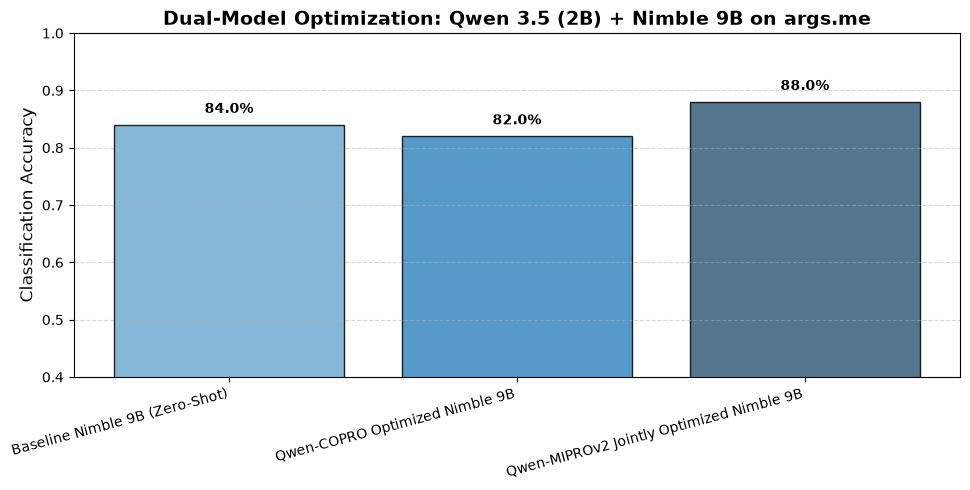

In [14]:
# 8. Benchmark Visualization
plt.figure(figsize=(10, 5))
palette = sns.color_palette("Blues_d", len(final_df))

bars = plt.bar(final_df["Pipeline"], final_df["Accuracy"], color=palette, edgecolor="black", alpha=0.85)
plt.ylabel("Classification Accuracy", fontsize=12)
plt.title("Dual-Model Optimization: Qwen 3.5 (2B) + Nimble 9B on args.me", fontsize=14, fontweight="bold")
plt.ylim(0.4, 1.0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.015, f"{yval*100:.1f}%", ha="center", va="bottom", fontweight="bold")

plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()